In [1]:
import sys
sys.path.append('../')

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import seaborn as sns
import model
import json, csv
import mvpy
import plots

from copy import deepcopy

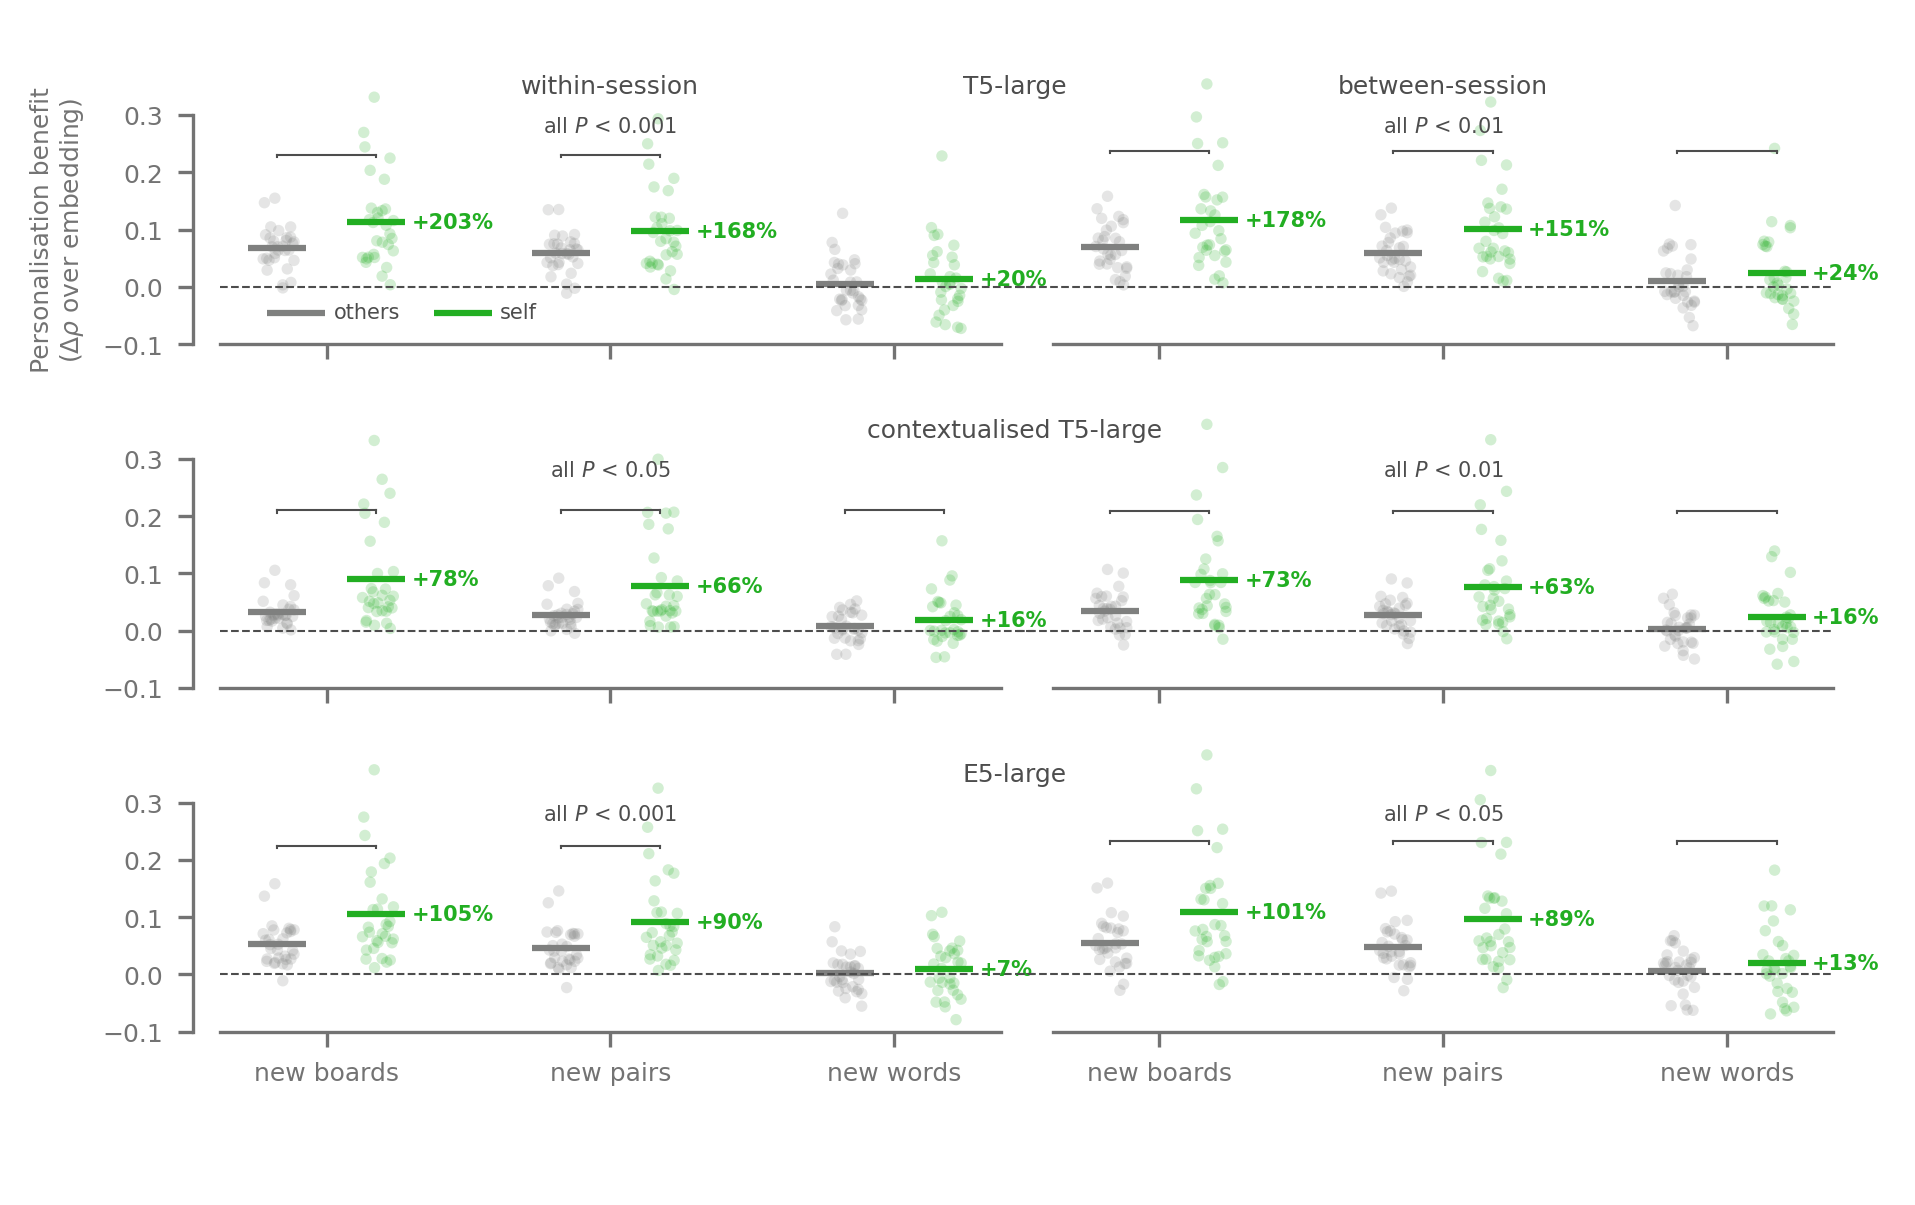

In [42]:
hypothesis_test = 'sign'
hypothesis_alternative = 'greater'
hypothesis_method = 'holm'
hypothesis_se = 'within'
show_pct = True

run = 1
exp = 1
Ps = ['', 'pns_', 'uns_']

mods = [
    't5-large',
    't5-large-context',
    'e5-large'
]

mods_label = [
    fr'T5-large',
    fr'contextualised T5-large',
    fr'E5-large',
]

cols = np.array([
    plots.colours.HL_EMBEDDING,
    plots.colours.HL_OTHERS,
    plots.colours.HL_SELF
])

cols2 = np.array([
    plots.colours.CM_RDM_CL(0.00),
    plots.colours.CM_RDM_CL(0.20),
    plots.colours.CM_RDM_CL(0.40)
])

X_jitter = 0.125 * np.random.uniform(low = -1.0, high = 1.0, size = (30,))

fig, ax = plt.subplots(figsize = (6.4, 4.0), dpi = 300)

# remove axis
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
ax.axis('off')

for m_i, mod in enumerate(mods):

    # within-session
    values = np.zeros((len(Ps) * 3, 30))
    deltas = np.zeros((len(Ps) * 2, 30))

    R = torch.load(f'../data/ds-exp{exp}/derivatives/run-00{run}/tasks/task-matrain_bse0-{mod}_mod-delta.pt', map_location=torch.device('cpu'))

    for i, P in enumerate(Ps):
        R_base = R[f'{P}rho_BE'].squeeze().cpu().numpy().diagonal()
        R_indiv = R[f'{P}rho_BZ'].cpu().numpy().diagonal().squeeze()
        R_group = R[f'{P}rho_BZ'].cpu().numpy()
        R_group = R_group[np.eye(R_group.shape[0], dtype = bool) == False].reshape((R_group.shape[0], R_group.shape[0] - 1)).mean(-1)

        R_a = np.array([R_base, R_group, R_indiv])
        R_b = R_a[1:] - R_a[0]

        deltas[i*2,:] = R_b[0,:]
        deltas[i*2+1] = R_b[1,:]

        values[i*3,:] = R_a[0]
        values[i*3+1,:] = R_a[1]
        values[i*3+2,:] = R_a[2]

    ax5 = ax.inset_axes([0.04, 0.725 - 0.3 * m_i, 0.45, 0.20])

    offset = 0

    for i, R_i in enumerate(deltas):
        x_off = 0.15 * 2 * (i % 2 - 0.5)

        mu = R_i.mean()
        se = model.stats.bootstrap_se(R_i)
        x_i = i + X_jitter - x_off

        if offset < (mu + 1.96 * se):
            offset = mu + 1.96 * se

        label = None
        if i == 0:
            label = 'others'
        elif i == 1:
            label = 'self'
        ax5.scatter(x_i, R_i, marker = '.', edgecolor = 'None', facecolor = cols[i % 2 + 1], s = 30, alpha = 0.2, clip_on = False)
        ax5.scatter([i - x_off], [mu], color = cols[i % 2 + 1], label = label, marker = '_', s = 200, clip_on = False, zorder = 2)

    ax5.patch.set_facecolor('None')
    sns.despine(ax = ax5)

    # significance
    count = 0.0
    gain = 0.015
    min_p = 0.0

    design = [(1, 0), (3, 2), (5, 4)]
    group = model.stats.sample_tests(deltas, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)
    pairwise = model.stats.pairwise_tests(deltas, design, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)

    model.stats.save_results(group, f'./deliverable/csv/suppfig4/{mod}_wthn_group.csv')
    model.stats.save_results(pairwise, f'./deliverable/csv/suppfig4/{mod}_wthn_pairs-0.csv')

    for i, (ii, jj) in enumerate(design):
        p_i = pairwise[i]['p_cor']
        if p_i < .05:
            sig_off = np.abs(x_off)

            if p_i > min_p:
                min_p = p_i

            sig = 'n.s.' if p_i > 0.05 else '*' if p_i > 1e-2 else '**' if p_i > 1e-3 else '***'
            yy = 0.09 + offset + count * gain
            ax5.plot([ii-sig_off, jj+sig_off], [yy, yy], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
            ax5.plot([ii-sig_off, ii-sig_off], [yy, yy - gain / 4], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
            ax5.plot([jj+sig_off, jj+sig_off], [yy, yy - gain / 4], color = plots.colours.H2, linewidth = 0.5, clip_on = False)

    rep_p = 'n.s.' if min_p > .05 else fr'$P$ < 0.05' if min_p > 1e-2 else '$P$ < 0.01' if min_p > 1e-3 else '$P$ < 0.001'
    ax5.annotate(f'all {rep_p}', xy = (0, 0), xytext = (2.5, 0.28), ha = 'center', va = 'center', fontsize = 5, color = plots.colours.H2)

    design = [
        (1, 0), (2, 0), (2, 1), # new boards: G > B; I > B; I > G
        (4, 3), (5, 3), (5, 4), # new pairs:  G > B; I > B; I > G
        (7, 6), (8, 6), (8, 7)  # new words:  G > B; I > B; I > G
    ]
    pairwise = model.stats.pairwise_tests(values, design, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)
    model.stats.save_results(pairwise, f'./deliverable/csv/suppfig4/{mod}_wthn_pairs-1.csv')

    if show_pct:
        #xoff, yoff = 0.0, 0.02
        xoff, yoff = 0.25, 0.0
        fs, fw = 5, 'semibold'
        bbs, bbc, bba = 'square,pad=.1', 'white', 0.4

        mu = int(round(pairwise[1]['pct_mu']))
        y = pairwise[1]['mu']
        ax5.annotate(f'+{mu}%', xy = (0, 0), xytext = (1 - sig_off + xoff, y + yoff), ha = 'left', va = 'center', fontsize = fs, fontweight = fw, color = cols[2], annotation_clip = False)
        #ax5.annotate(f'+{mu}%', xy = (0, 0), xytext = (1 - sig_off + xoff, y + yoff), ha = 'center', va = 'center', fontsize = fs, fontweight = fw, color = cols[2], annotation_clip = False, bbox = dict(boxstyle = bbs, edgecolor = 'None', facecolor = bbc, alpha = bba))

        mu = int(round(pairwise[4]['pct_mu']))
        y = pairwise[4]['mu']
        ax5.annotate(f'+{mu}%', xy = (0, 0), xytext = (3 - sig_off + xoff, y + yoff), ha = 'left', va = 'center', fontsize = fs, fontweight = fw, color = cols[2], annotation_clip = False)
        #ax5.annotate(f'+{mu}%', xy = (0, 0), xytext = (3 - sig_off + xoff, y + yoff), ha = 'center', va = 'center', fontsize = fs, fontweight = fw, color = cols[2], annotation_clip = False, bbox = dict(boxstyle = bbs, edgecolor = 'None', facecolor = bbc, alpha = bba))

        mu = int(round(pairwise[7]['pct_mu']))
        y = pairwise[7]['mu']
        ax5.annotate(f'+{mu}%', xy = (0, 0), xytext = (5 - sig_off + xoff, y + yoff), ha = 'left', va = 'center', fontsize = fs, fontweight = fw, color = cols[2], annotation_clip = False)
        #ax5.annotate(f'+{mu}%', xy = (0, 0), xytext = (5 - sig_off + xoff, y + yoff), ha = 'center', va = 'center', fontsize = fs, fontweight = fw, color = cols[2], annotation_clip = False, bbox = dict(boxstyle = bbs, edgecolor = 'None', facecolor = bbc, alpha = bba))

    # between-session
    values = np.zeros((len(Ps) * 3, 30))
    deltas = np.zeros((len(Ps) * 2, 30))

    R = torch.load(f'../data/ds-exp{exp}/derivatives/run-00{run}/tasks/task-macross_bse0-{mod}_mod-delta.pt', map_location=torch.device('cpu'))

    for i, P in enumerate(Ps):
        R_base = R[f'{P}rho_BE'].squeeze().cpu().numpy().diagonal()
        R_indiv = R[f'{P}rho_BZ'].cpu().numpy().diagonal().squeeze()
        R_group = R[f'{P}rho_BZ'].cpu().numpy()
        R_group = R_group[np.eye(R_group.shape[0], dtype = bool) == False].reshape((R_group.shape[0], R_group.shape[0] - 1)).mean(-1)

        R_a = np.array([R_base, R_group, R_indiv])
        R_b = R_a[1:] - R_a[0]

        deltas[i*2,:] = R_b[0,:]
        deltas[i*2+1] = R_b[1,:]

        values[i*3,:] = R_a[0]
        values[i*3+1,:] = R_a[1]
        values[i*3+2,:] = R_a[2]

    ax6 = ax.inset_axes([0.52, 0.725 - 0.3 * m_i, 0.45, 0.20])

    offset = 0

    for i, R_i in enumerate(deltas):
        x_off = 0.15 * 2 * (i % 2 - 0.5)

        mu = R_i.mean()
        se = model.stats.bootstrap_se(R_i)
        x_i = i + X_jitter - x_off

        if offset < (mu + 1.96 * se):
            offset = mu + 1.96 * se

        ax6.scatter(x_i, R_i, marker = '.', edgecolor = 'None', facecolor = cols[i % 2 + 1], s = 30, alpha = 0.2, clip_on = False)
        ax6.scatter([i - x_off], [mu], color = cols[i % 2 + 1], marker = '_', s = 200, clip_on = False, zorder = 2)

    ax6.patch.set_facecolor('None')
    sns.despine(ax = ax6)

    design = [(1, 0), (3, 2), (5, 4)]
    group = model.stats.sample_tests(deltas, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)
    pairwise = model.stats.pairwise_tests(deltas, design, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)

    model.stats.save_results(group, f'./deliverable/csv/suppfig4/{mod}_btwn_group.csv')
    model.stats.save_results(pairwise, f'./deliverable/csv/suppfig4/{mod}_btwn_pairs-0.csv')

    # significance
    count = 0.0
    min_p = 0.0

    for i, (ii, jj) in enumerate(design):
        p_i = pairwise[i]['p_cor']
        if p_i < .05:
            sig_off = np.abs(x_off)

            if p_i > min_p:
                min_p = p_i

            sig = 'n.s.' if p_i > 0.05 else '*' if p_i > 1e-2 else '**' if p_i > 1e-3 else '***'
            yy = 0.09 + offset + count * gain
            ax6.plot([ii-sig_off, jj+sig_off], [yy, yy], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
            ax6.plot([ii-sig_off, ii-sig_off], [yy, yy - gain / 4], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
            ax6.plot([jj+sig_off, jj+sig_off], [yy, yy - gain / 4], color = plots.colours.H2, linewidth = 0.5, clip_on = False)

    rep_p = 'n.s.' if min_p > .05 else fr'$P$ < 0.05' if min_p > 1e-2 else '$P$ < 0.01' if min_p > 1e-3 else '$P$ < 0.001'
    ax6.annotate(f'all {rep_p}', xy = (0, 0), xytext = (2.5, 0.28), ha = 'center', va = 'center', fontsize = 5, color = plots.colours.H2)

    design = [
        (1, 0), (2, 0), (2, 1), # new boards: G > B; I > B; I > G
        (4, 3), (5, 3), (5, 4), # new pairs:  G > B; I > B; I > G
        (7, 6), (8, 6), (8, 7)  # new words:  G > B; I > B; I > G
    ]
    pairwise = model.stats.pairwise_tests(values, design, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)
    model.stats.save_results(pairwise, f'./deliverable/csv/suppfig4/{mod}_btwn_pairs-1.csv')

    if show_pct:
        #xoff, yoff = 0.0, 0.02
        xoff, yoff = 0.25, 0.0
        fs, fw = 5, 'semibold'
        bbs, bbc, bba = 'square,pad=.1', 'white', 0.4

        mu = int(round(pairwise[1]['pct_mu']))
        y = pairwise[1]['mu']
        ax6.annotate(f'+{mu}%', xy = (0, 0), xytext = (1 - sig_off + xoff, y + yoff), ha = 'left', va = 'center', fontsize = fs, fontweight = fw, color = cols[2], annotation_clip = False)
        #ax6.annotate(f'+{mu}%', xy = (0, 0), xytext = (1 - sig_off + xoff, y + yoff), ha = 'center', va = 'center', fontsize = fs, fontweight = fw, color = cols[2], annotation_clip = False, bbox = dict(boxstyle = bbs, edgecolor = 'None', facecolor = bbc, alpha = bba))

        mu = int(round(pairwise[4]['pct_mu']))
        y = pairwise[4]['mu']
        ax6.annotate(f'+{mu}%', xy = (0, 0), xytext = (3 - sig_off + xoff, y + yoff), ha = 'left', va = 'center', fontsize = fs, fontweight = fw, color = cols[2], annotation_clip = False)
        #ax6.annotate(f'+{mu}%', xy = (0, 0), xytext = (3 - sig_off + xoff, y + yoff), ha = 'center', va = 'center', fontsize = fs, fontweight = fw, color = cols[2], annotation_clip = False, bbox = dict(boxstyle = bbs, edgecolor = 'None', facecolor = bbc, alpha = bba))

        mu = int(round(pairwise[7]['pct_mu']))
        y = pairwise[7]['mu']
        ax6.annotate(f'+{mu}%', xy = (0, 0), xytext = (5 - sig_off + xoff, y + yoff), ha = 'left', va = 'center', fontsize = fs, fontweight = fw, color = cols[2], annotation_clip = False)
        #ax6.annotate(f'+{mu}%', xy = (0, 0), xytext = (5 - sig_off + xoff, y + yoff), ha = 'center', va = 'center', fontsize = fs, fontweight = fw, color = cols[2], annotation_clip = False, bbox = dict(boxstyle = bbs, edgecolor = 'None', facecolor = bbc, alpha = bba))

    # legend
    if (m_i == 0):
        ax5.legend(
            bbox_to_anchor = (0.43, 0.265),
            frameon = False,
            ncols = 2,
            fontsize = 5,
            labelcolor = plots.colours.H2
        )

    for i, ax_i in enumerate([ax5, ax6]):
        yticks = [-0.1, 0.0, 0.1, 0.2, 0.3] if i == 0 else []
        ylab = 'Personalisation benefit\n' + fr'($\Delta\rho$ over embedding)' if (i == 0) and (m_i == 0) else ''
        xticks = ['new boards', 'new pairs', 'new words'] if (m_i == 2) else []
        title = fr'within-session' if (i == 0) else 'between-session'
        if m_i != 0: title = ''
        
        ax_i.annotate(title, xy = (0, 0), xytext = (2.5, 0.35), ha = 'center', va = 'center', color = plots.colours.H2, fontsize = 6, annotation_clip = False)

        ax_i.set_yticks(yticks)
        ax_i.set_ylim([-0.1, 0.3])
        ax_i.set_ylabel(ylab)
        ax_i.set_xticks([0.5, 2.5, 4.5])
        ax_i.set_xticklabels(xticks)
        ax_i.set_xlim([-0.25, 5.25])
        
        ax_i.yaxis.label.set_color(plots.colours.H3)
        ax_i.xaxis.label.set_color(plots.colours.H3)
        ax_i.tick_params(axis = 'x', colors = plots.colours.H3)
        ax_i.tick_params(axis = 'y', colors = plots.colours.H3)
        ax_i.spines['bottom'].set_color(plots.colours.H3)
        ax_i.spines['left'].set_color(plots.colours.H3)

        if i == 1:
            ax_i.spines['left'].set_visible(False)

        if i == 0:
            ax_i.spines['left'].set_position(('axes', -0.035))

        xext = 0.25
        xmin, xmax = (0.0, xext) if i == 0 else (-xext, 0.0)
        ax_i.plot([-0.25+xmin, 5.25+xmax], [0, 0], linewidth = 0.5, color = plots.colours.H2, linestyle = '--', clip_on = False)        
        
    ax5.annotate(
        mods_label[m_i],
        xy = (0, 0),
        xytext = (5.35, 0.35),
        ha = 'center',
        va = 'center',
        fontsize = 6,
        color = plots.colours.H2,
        annotation_clip = False
    )

'''
cosmetics
'''

fig.tight_layout()

ax.axis('off')

fig.savefig('./deliverable/png/suppfig4.png', dpi = 900)
fig.savefig('./deliverable/pdf/suppfig4.pdf', dpi = 900, format = 'pdf')
fig.savefig('./deliverable/svg/suppfig4.svg', dpi = 900, format = 'svg')